## 0. Install and import libraries
Run the install command once if packages are missing. `mlxtend` is used only for association rules.

In [216]:
# If required, run once in Jupyter:
# %pip install pandas numpy matplotlib seaborn scikit-learn statsmodels mlxtend

In [217]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, log_loss, roc_auc_score, precision_score,
    recall_score, f1_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.model_selection import validation_curve

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

## UNIT I – Introduction, dataset exploration and preprocessing
### Practical 1: Load and explore data

In [218]:
DATA_PATH = "Social_media_impact_on_life.csv"  # change path if needed
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())
display(df.tail())
df.info()
display(df.describe(include="all").T)
print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nMissing values:\\n", df.isna().sum())

Shape: (4500, 16)


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
4495,STU_2028495,16,Male,High School,YouTube,5.8,1.2,Smartphone,7.8,3,True,Sometimes,11.0,79,2.85,Beneficial
4496,STU_2028496,19,Female,Undergraduate,LinkedIn,3.8,3.0,Smartphone,6.6,3,False,Frequently,9.0,83,3.37,Beneficial
4497,STU_2028497,19,Male,Undergraduate,Instagram,7.7,1.1,Smartphone,6.0,2,True,Frequently,13.0,73,3.16,Beneficial
4498,STU_2028498,16,Male,High School,LinkedIn,4.6,3.3,Laptop/PC,7.1,3,False,Sometimes,22.0,87,3.50,Beneficial
4499,STU_2028499,24,Male,Undergraduate,Instagram,1.8,2.1,Smartphone,6.8,3,True,Frequently,10.0,98,3.73,Beneficial


<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   str    
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   str    
 3   Academic_Level               4500 non-null   str    
 4   Primary_Platform             4500 non-null   str    
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   str    
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   str    
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Index          

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Student_ID,4500,4500,STU_2024000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,4500.0,NaN,NaN,NaN,18.703333,1.981182,15.0,17.0,19.0,20.0,26.0
Gender,4500,4,Female,2234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Academic_Level,4500,3,Undergraduate,2777,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Primary_Platform,4500,7,Instagram,1453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Daily_Usage_Hours,4500.0,NaN,NaN,NaN,5.295933,2.604497,0.9,3.4,4.7,6.6,14.0
Weekend_Extra_Hours,4500.0,NaN,NaN,NaN,1.796844,0.699245,0.0,1.3,1.8,2.3,4.5
Device_Type,4500,3,Smartphone,3775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Duration_Hours,4500.0,NaN,NaN,NaN,6.701333,1.189998,3.0,6.0,6.8,7.5,10.5
Sleep_Quality_Score,4500.0,NaN,NaN,NaN,2.472,1.030484,1.0,2.0,3.0,3.0,5.0


\nDuplicate rows: 0
\nMissing values:\n Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64


In [219]:
# Variable types
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "bool"]).columns.tolist()
print("Numeric columns:", numeric_cols)
print("Categorical/Boolean columns:", categorical_cols)
print("\\nUnique values per column:\\n", df.nunique())

Numeric columns: ['Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Perceived_Stress_Score', 'Mental_Health_Index', 'Academic_Performance_GPA']
Categorical/Boolean columns: ['Student_ID', 'Gender', 'Academic_Level', 'Primary_Platform', 'Device_Type', 'Late_Night_Usage', 'Social_Comparison_Frequency', 'Overall_Impact']
\nUnique values per column:\n Student_ID                     4500
Age                              12
Gender                            4
Academic_Level                    3
Primary_Platform                  7
Daily_Usage_Hours               129
Weekend_Extra_Hours              43
Device_Type                       3
Sleep_Duration_Hours             73
Sleep_Quality_Score               5
Late_Night_Usage                  2
Social_Comparison_Frequency       5
Perceived_Stress_Score           41
Mental_Health_Index              67
Academic_Performance_GPA        194
Overall_Impact                    3
dtype: int64


### Exploratory graphs (EDA)

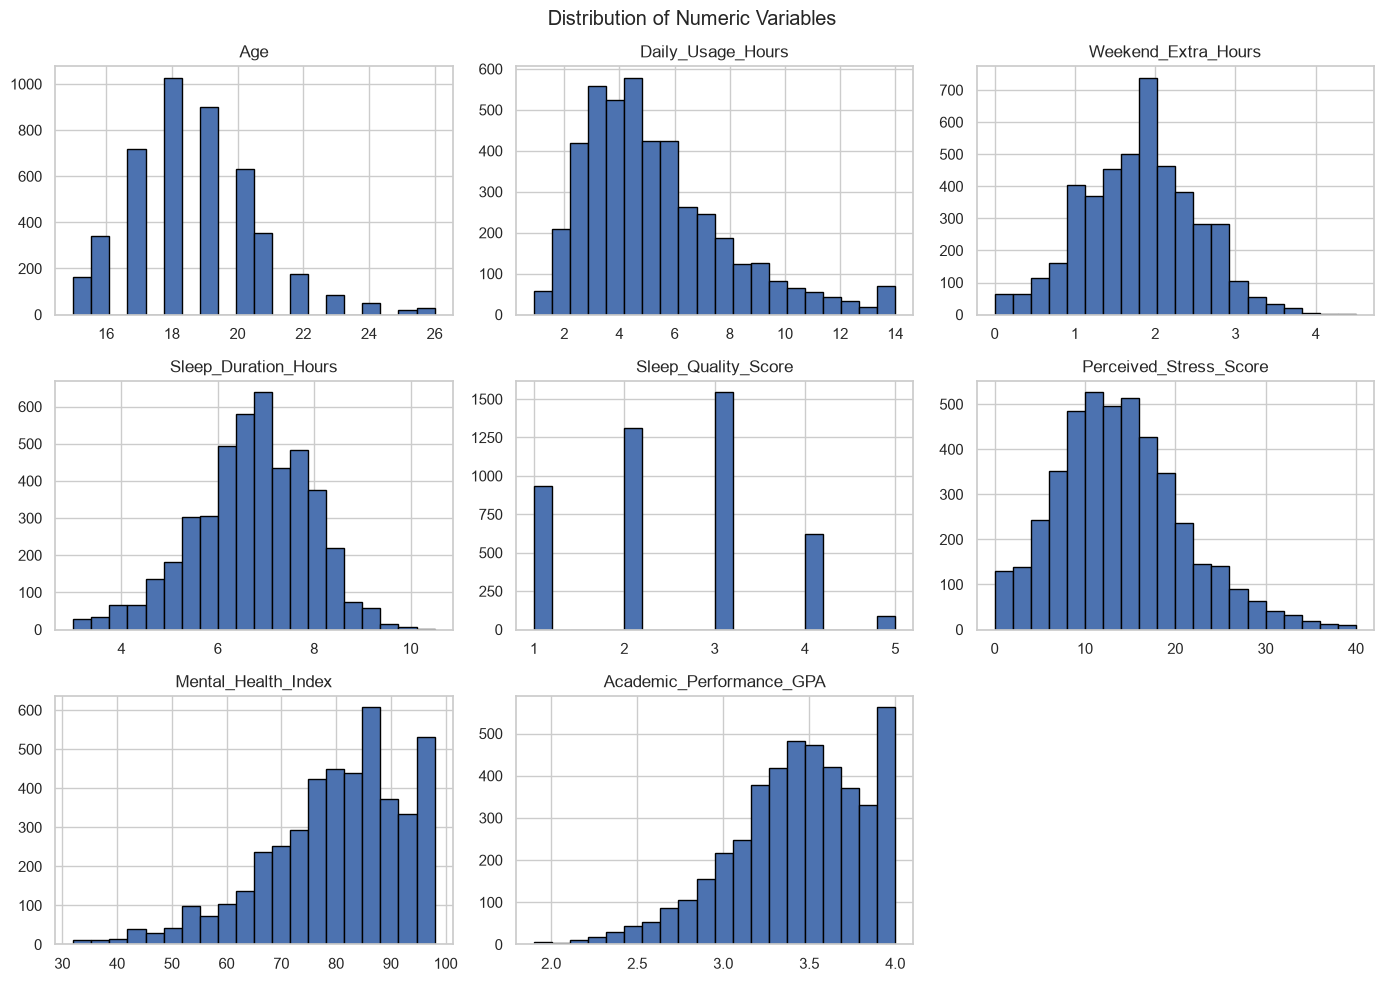

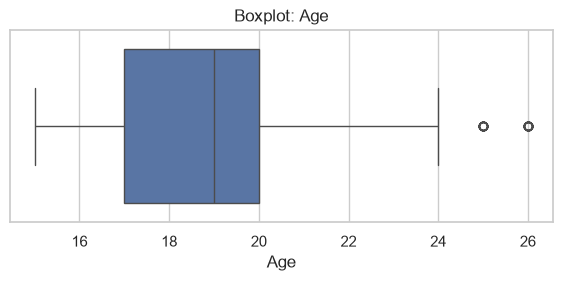

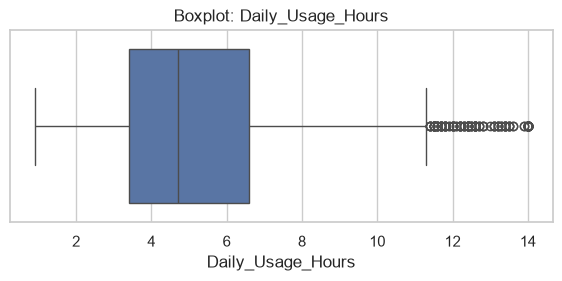

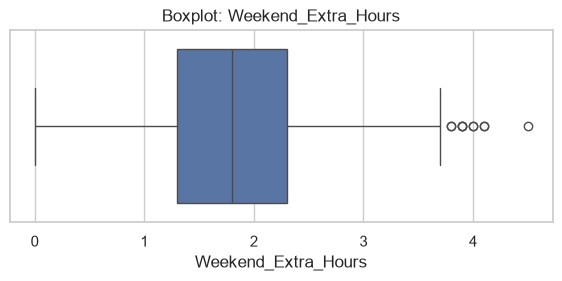

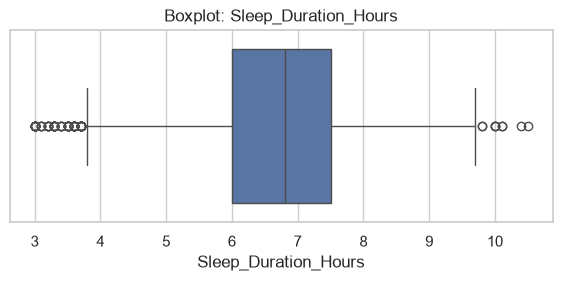

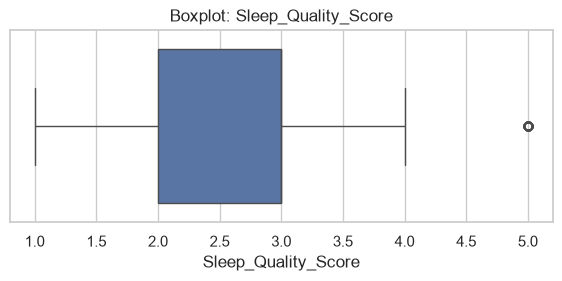

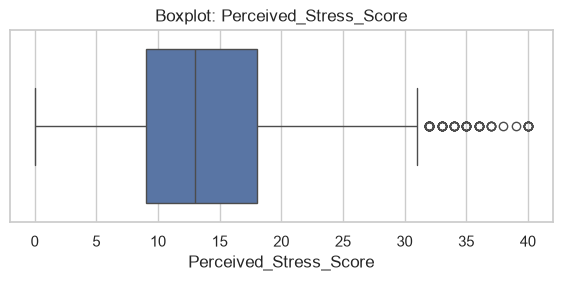

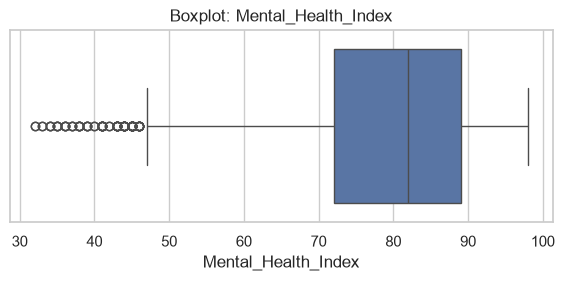

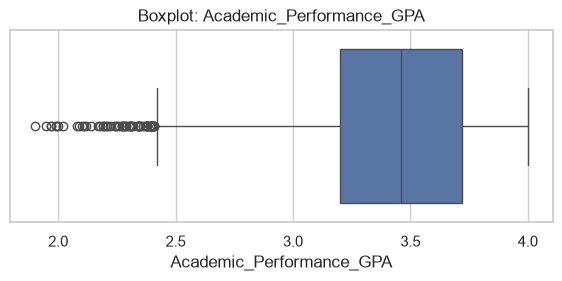

In [220]:
# 1. Histograms of numeric variables
df[numeric_cols].hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distribution of Numeric Variables")
plt.tight_layout()
plt.show()

# 2. Boxplots – detect possible outliers
for col in numeric_cols:
    plt.figure(figsize=(7, 2.5))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot: {col}")
    plt.show()

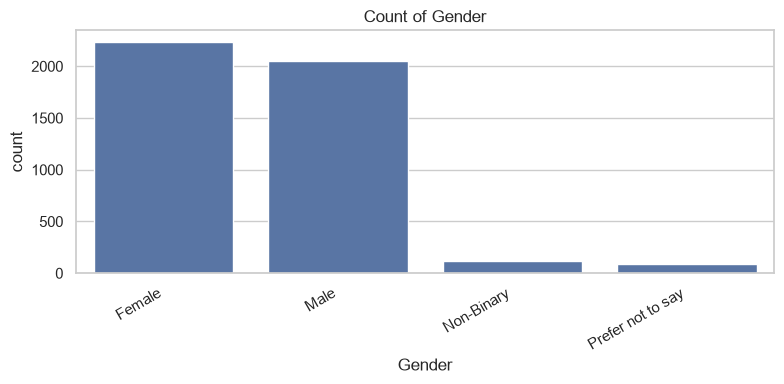

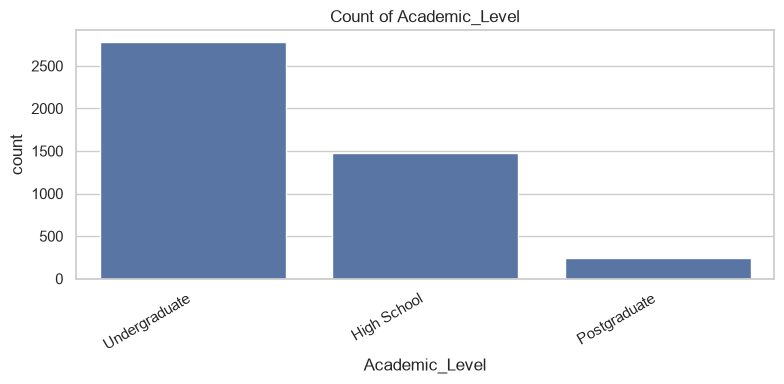

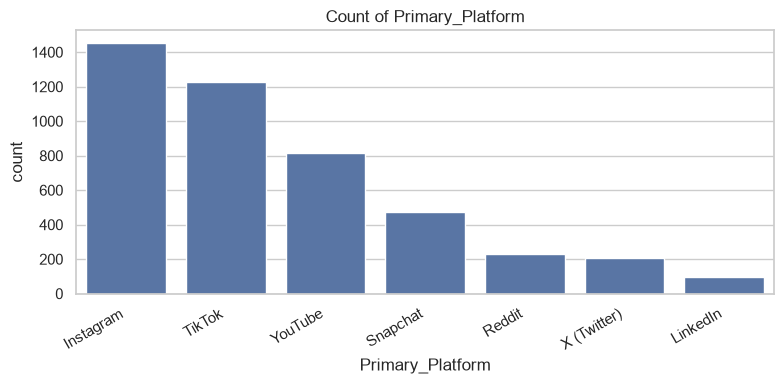

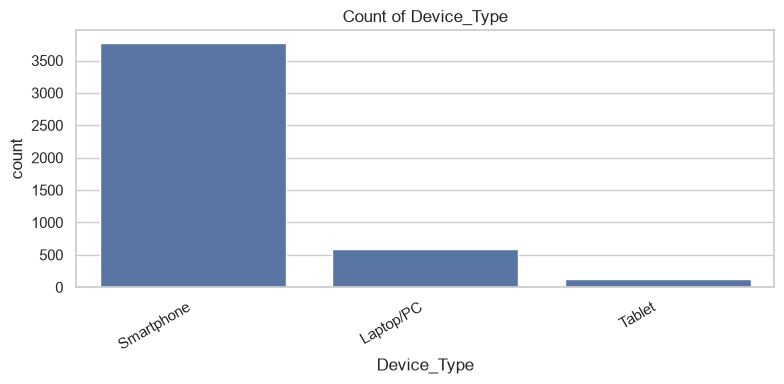

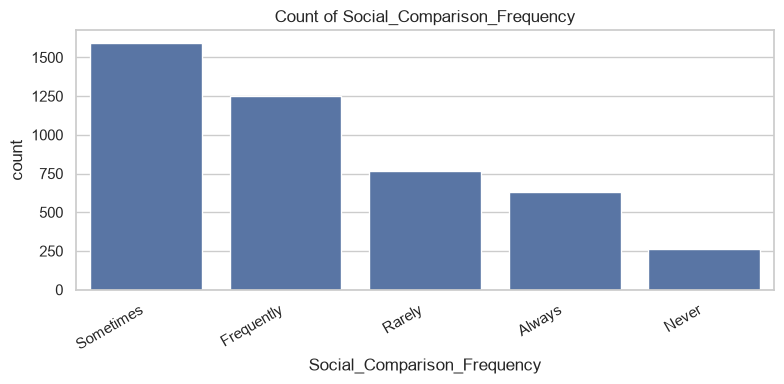

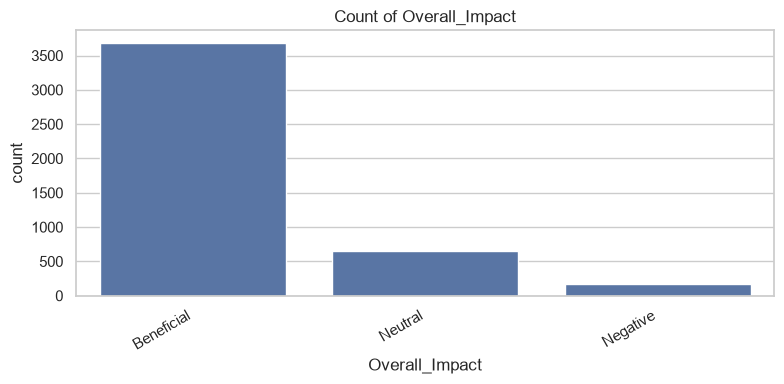

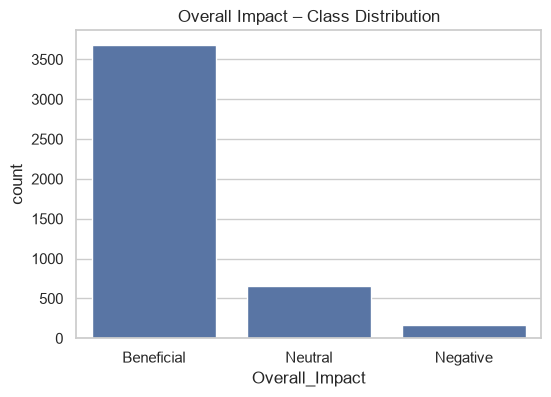

In [221]:
# 3. Category counts
for col in ["Gender", "Academic_Level", "Primary_Platform", "Device_Type",
            "Social_Comparison_Frequency", "Overall_Impact"]:
    plt.figure(figsize=(8, 4))
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order)
    plt.title(f"Count of {col}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# 4. Target class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Overall_Impact", order=df["Overall_Impact"].value_counts().index)
plt.title("Overall Impact – Class Distribution")
plt.show()

### Practical 2: Data preprocessing – missing values, encoding and normalization

In [222]:
# Work on a copy. Remove identifier from predictive features.
data = df.drop(columns=["Student_ID"], errors="ignore").copy()

# Fill numeric missing values with median; categorical with mode.
for col in data.select_dtypes(include=np.number).columns:
    data[col] = data[col].fillna(data[col].median())

for col in data.select_dtypes(include=["object", "bool"]).columns:
    if data[col].isna().any():
        data[col] = data[col].fillna(data[col].mode()[0])

print("Missing values after simple imputation:")
print(data.isna().sum().sum())
display(data.head())

Missing values after simple imputation:
0


,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [223]:
# Normalization examples (fit only for demonstration; for ML use Pipeline below)
scale_cols = data.select_dtypes(include=np.number).columns
standard_scaled = pd.DataFrame(
    StandardScaler().fit_transform(data[scale_cols]),
    columns=scale_cols
)
minmax_scaled = pd.DataFrame(
    MinMaxScaler().fit_transform(data[scale_cols]),
    columns=scale_cols
)
display(standard_scaled.head())
display(minmax_scaled.head())

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
0,0.149759,0.846348,-0.424569,-0.673465,-0.458088,0.922839,-0.533850,-1.799529
1,0.149759,-0.267234,-0.710623,1.007397,0.512438,0.496462,0.786578,-0.565323
2,-0.859852,2.151928,-0.138514,-1.261767,-1.428614,0.638587,-0.766867,-1.105289
3,-1.364657,0.270357,0.719650,0.755267,1.482964,0.212210,0.165200,-0.025358
4,-0.859852,-0.766426,1.148732,0.755267,1.482964,0.354336,0.320545,-0.051071


,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
0,0.363636,0.503817,0.333333,0.386667,0.25,0.500,0.621212,0.395238
1,0.363636,0.282443,0.288889,0.653333,0.50,0.425,0.878788,0.623810
2,0.181818,0.763359,0.377778,0.293333,0.00,0.450,0.575758,0.523810
3,0.090909,0.389313,0.511111,0.613333,0.75,0.375,0.757576,0.723810
4,0.181818,0.183206,0.577778,0.613333,0.75,0.400,0.787879,0.719048


## Common preprocessing pipelines
Pipelines prevent data leakage by learning imputation, encoding and scaling only from training data. `Overall_Impact` is the classification target. `Academic_Performance_GPA` is used as the main regression target.

In [224]:
TARGET_CLASS = "Overall_Impact"
TARGET_REG = "Academic_Performance_GPA"

# General helper: create a train/test-ready preprocessing transformer.
def make_preprocessor(X, scale_numeric=True):
    num_features = X.select_dtypes(include=np.number).columns.tolist()
    cat_features = X.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    numeric_transformer = Pipeline(num_steps)

    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_transformer, num_features),
        ("cat", categorical_transformer, cat_features)
    ])

## UNIT II – Supervised learning: Regression
### Simple Linear Regression
Example: predict GPA using daily social media usage hours.

Intercept: 3.984688216660773
Coefficient: -0.10551633088988348
MAE: 0.22693320069720152
MSE: 0.07839423736139688
RMSE: 0.27998970938482165
R-squared: 0.5318017633963583


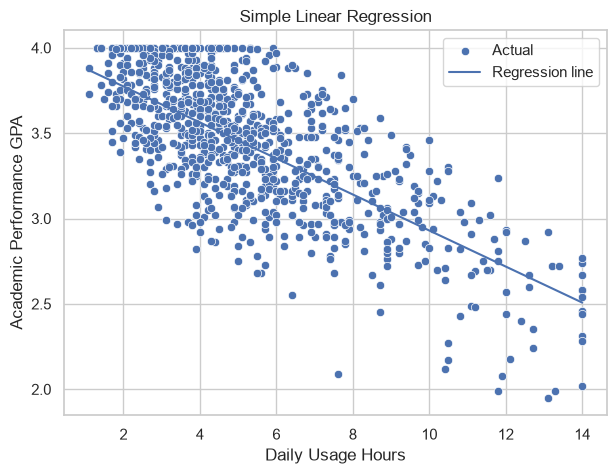

In [225]:
reg_data = df.dropna(subset=[TARGET_REG]).copy()
X_simple = reg_data[["Daily_Usage_Hours"]]
y_reg = reg_data[TARGET_REG]
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_reg, test_size=0.2, random_state=RANDOM_STATE
)
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)
pred_s = simple_model.predict(X_test_s)

print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("MAE:", mean_absolute_error(y_test_s, pred_s))
print("MSE:", mean_squared_error(y_test_s, pred_s))
print("RMSE:", np.sqrt(mean_squared_error(y_test_s, pred_s)))
print("R-squared:", r2_score(y_test_s, pred_s))

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_test_s["Daily_Usage_Hours"], y=y_test_s, label="Actual")
order = np.argsort(X_test_s["Daily_Usage_Hours"].values)
plt.plot(X_test_s["Daily_Usage_Hours"].values[order], pred_s[order], label="Regression line")
plt.xlabel("Daily Usage Hours"); plt.ylabel("Academic Performance GPA")
plt.title("Simple Linear Regression")
plt.legend(); plt.show()

### Multiple Linear Regression and OLS
Use available numeric/categorical predictors to estimate GPA. The ID is excluded.

MAE: 0.21791970062074303
MSE: 0.07249085198630108
RMSE: 0.26924125238585017
R2: 0.5670588781491911


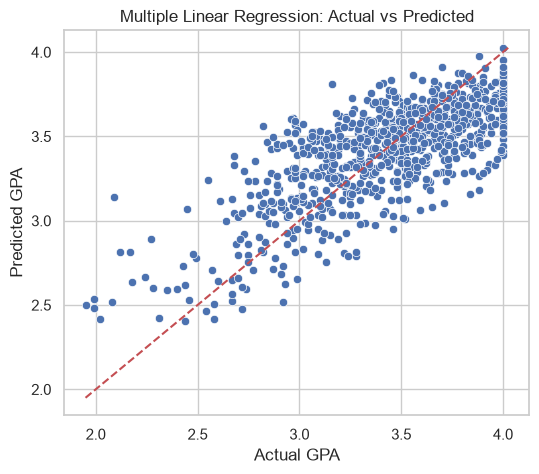

In [226]:
reg_features = [
    "Age", "Gender", "Academic_Level", "Primary_Platform", "Daily_Usage_Hours",
    "Weekend_Extra_Hours", "Device_Type", "Sleep_Duration_Hours",
    "Sleep_Quality_Score", "Late_Night_Usage", "Social_Comparison_Frequency",
    "Perceived_Stress_Score", "Mental_Health_Index"
]
reg_data = df.dropna(subset=[TARGET_REG]).copy()
X = reg_data[reg_features]
y = reg_data[TARGET_REG]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
multi_pipe = Pipeline([
    ("preprocess", make_preprocessor(X)),
    ("model", LinearRegression())
])
multi_pipe.fit(X_train, y_train)
pred = multi_pipe.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred))
print("MSE:", mean_squared_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2:", r2_score(y_test, pred))

plt.figure(figsize=(6, 5))
sns.scatterplot(x=y_test, y=pred)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual GPA"); plt.ylabel("Predicted GPA")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.show()

In [227]:
# Ordinary Least Squares (OLS) using statsmodels.
# This version uses numeric predictors and complete rows for transparent coefficient output.
import statsmodels.api as sm

ols_cols = ["Daily_Usage_Hours", "Weekend_Extra_Hours", "Sleep_Duration_Hours",
            "Sleep_Quality_Score", "Perceived_Stress_Score", "Mental_Health_Index"]
ols_data = df[ols_cols + [TARGET_REG]].dropna()
X_ols = sm.add_constant(ols_data[ols_cols])
ols_model = sm.OLS(ols_data[TARGET_REG], X_ols).fit()
print(ols_model.summary())

                               OLS Regression Results                               
Dep. Variable:     Academic_Performance_GPA   R-squared:                       0.542
Model:                                  OLS   Adj. R-squared:                  0.542
Method:                       Least Squares   F-statistic:                     861.1
Date:                      Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                              13:33:26   Log-Likelihood:                -410.76
No. Observations:                      4369   AIC:                             835.5
Df Residuals:                          4362   BIC:                             880.2
Df Model:                                 6                                         
Covariance Type:                  nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

### Polynomial Regression
Degree 2 example: GPA predicted from daily usage hours.

MAE: 0.22708146976000407
RMSE: 0.27993352613593264
R2: 0.531989643578953


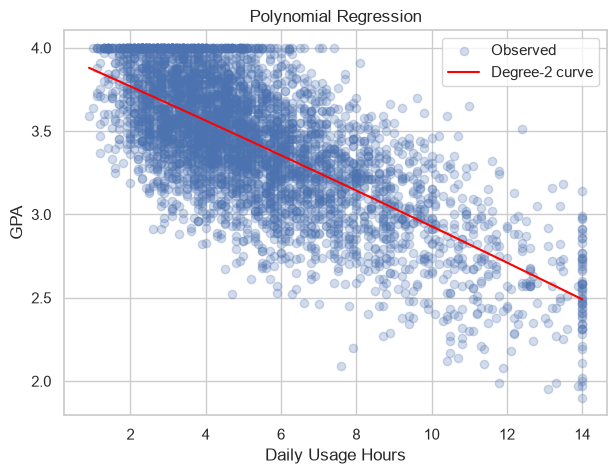

In [228]:
poly_data = df.dropna(subset=[TARGET_REG])
X_poly = poly_data[["Daily_Usage_Hours"]]
y_poly = poly_data[TARGET_REG]
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_poly, y_poly, test_size=0.2, random_state=RANDOM_STATE
)
poly_pipe = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scale", StandardScaler()),
    ("model", LinearRegression())
])
poly_pipe.fit(Xp_train, yp_train)
poly_pred = poly_pipe.predict(Xp_test)
print("MAE:", mean_absolute_error(yp_test, poly_pred))
print("RMSE:", np.sqrt(mean_squared_error(yp_test, poly_pred)))
print("R2:", r2_score(yp_test, poly_pred))

x_grid = np.linspace(X_poly.min().iloc[0], X_poly.max().iloc[0], 250).reshape(-1, 1)
plt.figure(figsize=(7, 5))
plt.scatter(X_poly, y_poly, alpha=.25, label="Observed")
plt.plot(x_grid, poly_pipe.predict(x_grid), color="red", label="Degree-2 curve")
plt.xlabel("Daily Usage Hours"); plt.ylabel("GPA")
plt.title("Polynomial Regression"); plt.legend(); plt.show()

### Correlation analysis and heatmap

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
Age,1.000000,-0.029603,0.002918,0.012631,0.030933,-0.020696,0.022555,0.028110
Daily_Usage_Hours,-0.029603,1.000000,-0.009572,-0.715903,-0.681290,0.754470,-0.849908,-0.710057
Weekend_Extra_Hours,0.002918,-0.009572,1.000000,0.016668,0.012124,0.001198,0.004026,0.012275
Sleep_Duration_Hours,0.012631,-0.715903,0.016668,1.000000,0.747737,-0.661657,0.774220,0.595263
Sleep_Quality_Score,0.030933,-0.681290,0.012124,0.747737,1.000000,-0.576453,0.662423,0.529270
Perceived_Stress_Score,-0.020696,0.754470,0.001198,-0.661657,-0.576453,1.000000,-0.773744,-0.650921
Mental_Health_Index,0.022555,-0.849908,0.004026,0.774220,0.662423,-0.773744,1.000000,0.659419
Academic_Performance_GPA,0.028110,-0.710057,0.012275,0.595263,0.529270,-0.650921,0.659419,1.000000


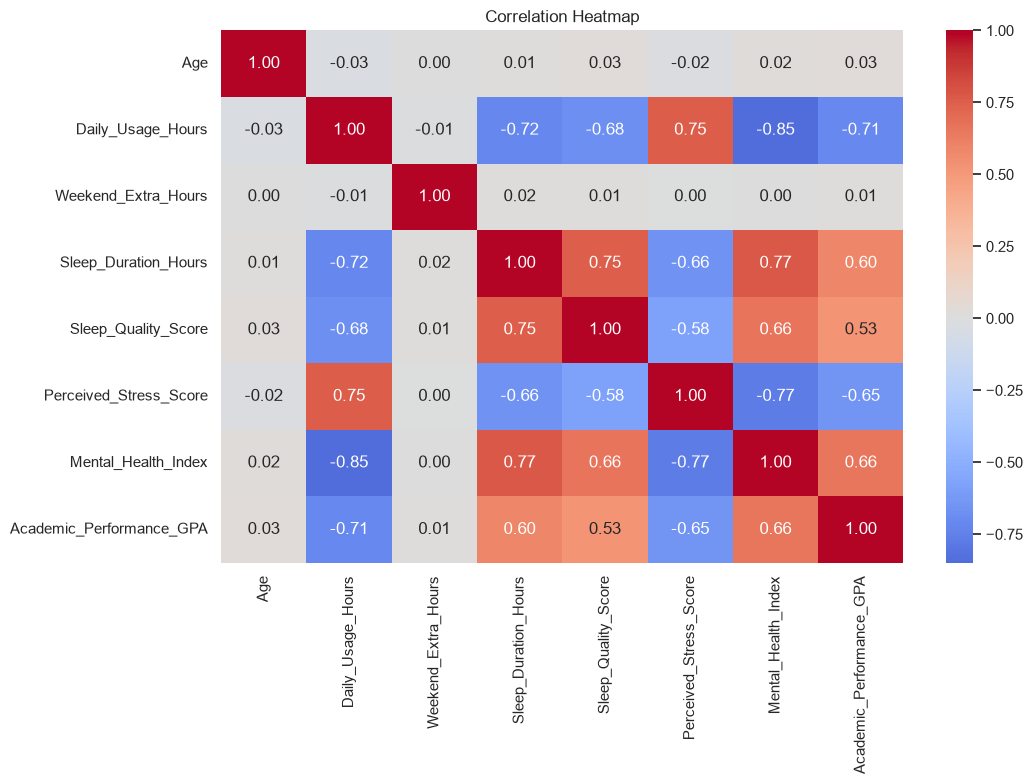

Academic_Performance_GPA    1.000000
Mental_Health_Index         0.659419
Sleep_Duration_Hours        0.595263
Sleep_Quality_Score         0.529270
Age                         0.028110
Weekend_Extra_Hours         0.012275
Perceived_Stress_Score     -0.650921
Daily_Usage_Hours          -0.710057
Name: Academic_Performance_GPA, dtype: float64

In [229]:
corr_cols = df.select_dtypes(include=np.number).columns
corr = df[corr_cols].corr()
display(corr)
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout(); plt.show()

# Correlation of numeric variables with GPA
display(corr[TARGET_REG].sort_values(ascending=False))

## UNIT III – Supervised learning: Classification
### Logistic Regression, KNN, Naive Bayes, Decision Tree and SVM
Target: `Overall_Impact` (Beneficial / Neutral / Negative).

In [230]:
class_features = [
    "Age", "Gender", "Academic_Level", "Primary_Platform", "Daily_Usage_Hours",
    "Weekend_Extra_Hours", "Device_Type", "Sleep_Duration_Hours",
    "Sleep_Quality_Score", "Late_Night_Usage", "Social_Comparison_Frequency",
    "Perceived_Stress_Score", "Mental_Health_Index", "Academic_Performance_GPA"
]
class_data = df.dropna(subset=[TARGET_CLASS]).copy()
Xc = class_data[class_features]
yc = class_data[TARGET_CLASS]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=RANDOM_STATE, stratify=yc
)
print(yc_train.value_counts(normalize=True))

Overall_Impact
Beneficial    0.818056
Neutral       0.145278
Negative      0.036667
Name: proportion, dtype: float64


\n===== Logistic Regression =====
Accuracy: 0.9811111111111112
Precision (macro): 0.9554921478701965
Recall (macro): 0.9445317135845679
F1 (macro): 0.94993390361378
              precision    recall  f1-score   support

  Beneficial       0.99      0.99      0.99       736
    Negative       0.94      0.91      0.92        33
     Neutral       0.94      0.93      0.93       131

    accuracy                           0.98       900
   macro avg       0.96      0.94      0.95       900
weighted avg       0.98      0.98      0.98       900



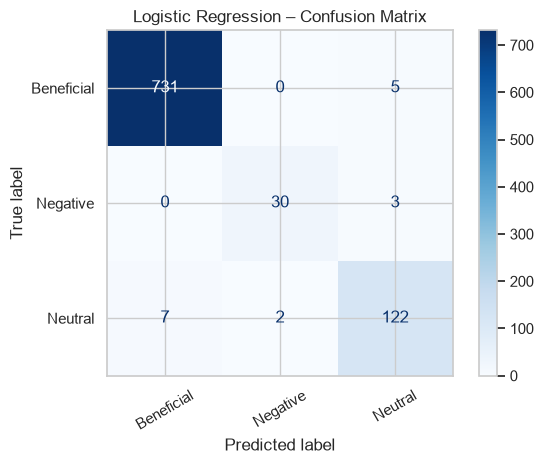

Log Loss: 0.05317270468381633
ROC AUC (macro OVR): 0.9981341881968273
\n===== K-Nearest Neighbors =====
Accuracy: 0.9344444444444444
Precision (macro): 0.8860761418232682
Recall (macro): 0.8187037567845733
F1 (macro): 0.8495447175389902
              precision    recall  f1-score   support

  Beneficial       0.96      0.98      0.97       736
    Negative       0.89      0.76      0.82        33
     Neutral       0.81      0.72      0.76       131

    accuracy                           0.93       900
   macro avg       0.89      0.82      0.85       900
weighted avg       0.93      0.93      0.93       900



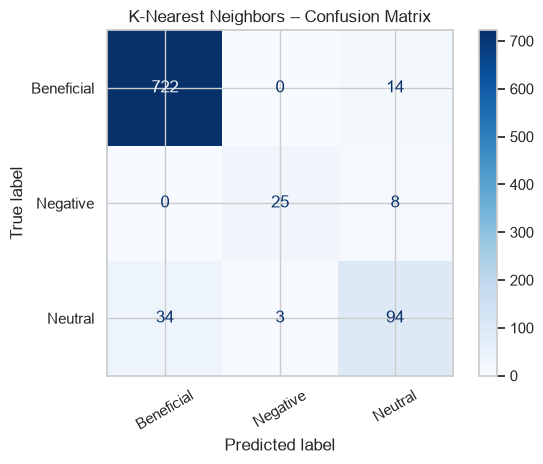

Log Loss: 0.386680456605271
ROC AUC (macro OVR): 0.9722171355466687
\n===== Gaussian Naive Bayes =====
Accuracy: 0.9233333333333333
Precision (macro): 0.7985287559042348
Recall (macro): 0.9000646818332679
F1 (macro): 0.8422652074157403
              precision    recall  f1-score   support

  Beneficial       0.99      0.94      0.96       736
    Negative       0.71      0.91      0.80        33
     Neutral       0.69      0.85      0.76       131

    accuracy                           0.92       900
   macro avg       0.80      0.90      0.84       900
weighted avg       0.94      0.92      0.93       900



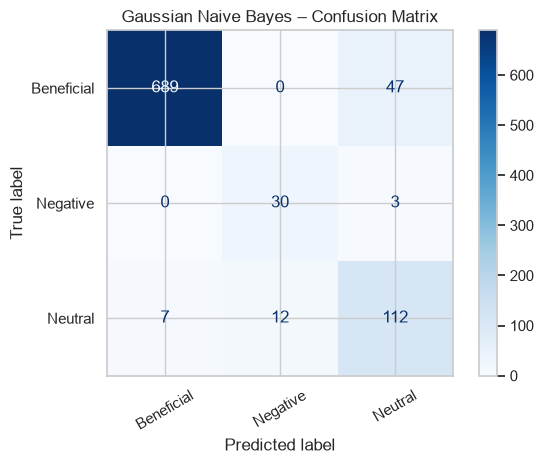

Log Loss: 0.3468842140897003
ROC AUC (macro OVR): 0.9823613588401875
\n===== Decision Tree =====
Accuracy: 0.9644444444444444
Precision (macro): 0.9066621761938031
Recall (macro): 0.9004273778273945
F1 (macro): 0.9031202129678583
              precision    recall  f1-score   support

  Beneficial       0.99      0.98      0.99       736
    Negative       0.87      0.82      0.84        33
     Neutral       0.86      0.90      0.88       131

    accuracy                           0.96       900
   macro avg       0.91      0.90      0.90       900
weighted avg       0.97      0.96      0.96       900



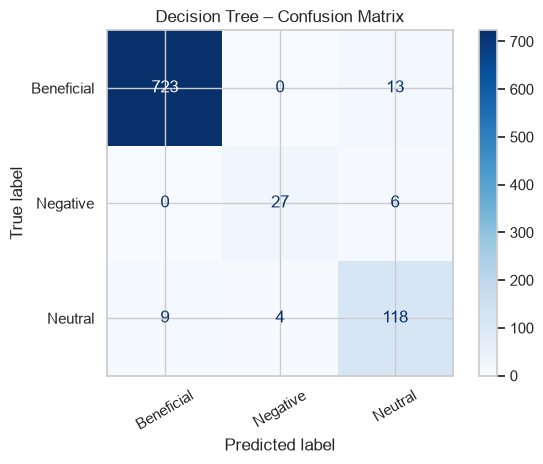

Log Loss: 0.3649771501649756
ROC AUC (macro OVR): 0.984802399492058
\n===== Support Vector Machine =====
Accuracy: 0.9722222222222222
Precision (macro): 0.9427637329859163
Recall (macro): 0.9228938907830377
F1 (macro): 0.9325277344849233
              precision    recall  f1-score   support

  Beneficial       0.99      0.99      0.99       736
    Negative       0.94      0.88      0.91        33
     Neutral       0.91      0.90      0.90       131

    accuracy                           0.97       900
   macro avg       0.94      0.92      0.93       900
weighted avg       0.97      0.97      0.97       900



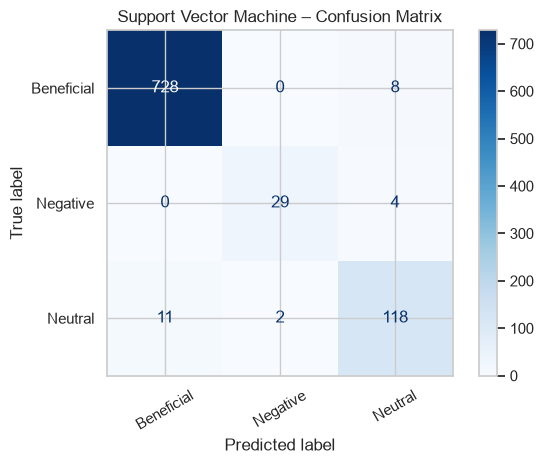

Log Loss: 0.06414479107758884
ROC AUC (macro OVR): 0.9972781612885658


In [231]:
def evaluate_classifier(name, estimator, X_train=Xc_train, X_test=Xc_test,
                         y_train=yc_train, y_test=yc_test):
    pipe = Pipeline([
        ("preprocess", make_preprocessor(X_train)),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    print(f"\\n===== {name} =====")
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision (macro):", precision_score(y_test, pred, average="macro", zero_division=0))
    print("Recall (macro):", recall_score(y_test, pred, average="macro", zero_division=0))
    print("F1 (macro):", f1_score(y_test, pred, average="macro", zero_division=0))
    print(classification_report(y_test, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=30, cmap="Blues")
    plt.title(f"{name} – Confusion Matrix"); plt.tight_layout(); plt.show()
    if hasattr(pipe.named_steps["model"], "predict_proba"):
        probabilities = pipe.predict_proba(X_test)
        print("Log Loss:", log_loss(y_test, probabilities, labels=pipe.classes_))
        try:
            print("ROC AUC (macro OVR):",
                  roc_auc_score(y_test, probabilities, multi_class="ovr", average="macro",
                                labels=pipe.classes_))
        except ValueError as e:
            print("ROC AUC not available:", e)
    return pipe

logistic_model = evaluate_classifier("Logistic Regression", LogisticRegression(max_iter=2000))
knn_model = evaluate_classifier("K-Nearest Neighbors", KNeighborsClassifier(n_neighbors=5))
nb_model = evaluate_classifier("Gaussian Naive Bayes", GaussianNB())
tree_model = evaluate_classifier("Decision Tree", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))
svm_model = evaluate_classifier("Support Vector Machine", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))

### Decision Tree visualization

### ROC curve / AUC (multi-class)
The metric cell above calculates macro one-vs-rest ROC AUC. This cell plots one-vs-rest ROC curves for the fitted logistic model.

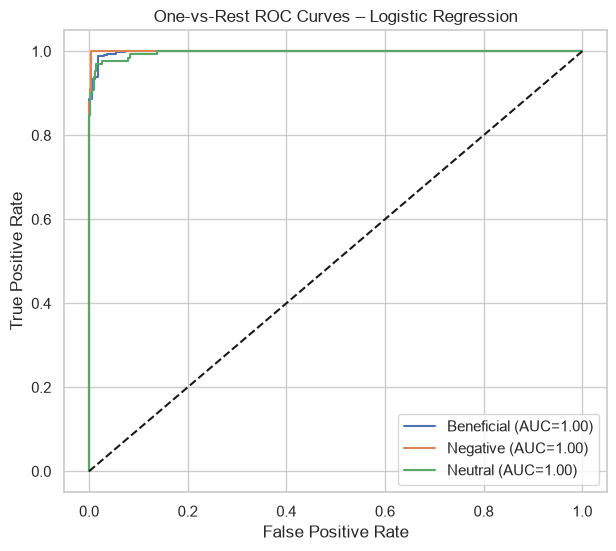

In [232]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

log_pipe = logistic_model
proba = log_pipe.predict_proba(Xc_test)
classes = log_pipe.classes_
y_bin = label_binarize(yc_test, classes=classes)
plt.figure(figsize=(7, 6))
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
    plt.plot(fpr, tpr, label=f"{cls} (AUC={auc(fpr, tpr):.2f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves – Logistic Regression")
plt.legend(); plt.show()

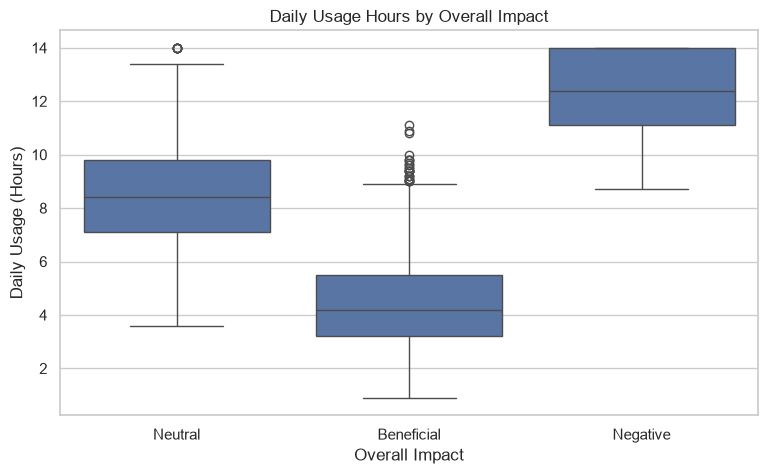

In [233]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Overall_Impact", y="Daily_Usage_Hours")
plt.title("Daily Usage Hours by Overall Impact")
plt.xlabel("Overall Impact")
plt.ylabel("Daily Usage (Hours)")
plt.show()

## UNIT IV – Unsupervised learning: Clustering and pattern detection
### K-Means and selecting K (Elbow + Silhouette)

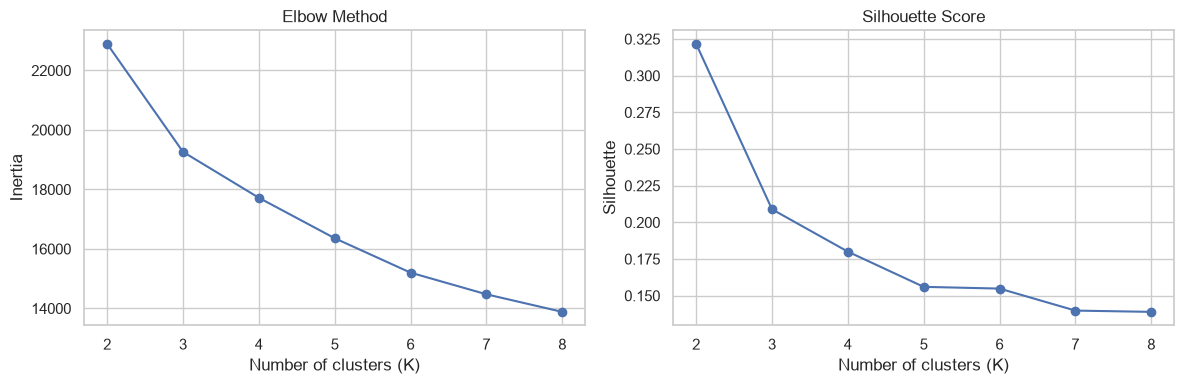

In [234]:
cluster_cols = ["Age", "Daily_Usage_Hours", "Weekend_Extra_Hours",
                "Sleep_Duration_Hours", "Sleep_Quality_Score",
                "Perceived_Stress_Score", "Mental_Health_Index",
                "Academic_Performance_GPA"]
cluster_data = df[cluster_cols].copy()
cluster_data = cluster_data.fillna(cluster_data.median())
X_cluster = StandardScaler().fit_transform(cluster_data)

inertias, silhouettes = [], []
k_values = range(2, 9)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_cluster)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(k_values), inertias, marker="o")
ax[0].set(title="Elbow Method", xlabel="Number of clusters (K)", ylabel="Inertia")
ax[1].plot(list(k_values), silhouettes, marker="o")
ax[1].set(title="Silhouette Score", xlabel="Number of clusters (K)", ylabel="Silhouette")
plt.tight_layout(); plt.show()

Silhouette score for K=3: 0.2089010650268102


,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
KMeans_Cluster,,,,,,,,
0,18.711477,5.530340,1.812487,6.380340,2.105207,14.788937,77.646121,3.363424
1,18.736486,3.410499,1.796206,7.643035,3.306133,8.395483,89.794699,3.696681
2,18.589337,9.887320,1.756196,4.961095,1.154179,24.216570,58.406340,2.871064


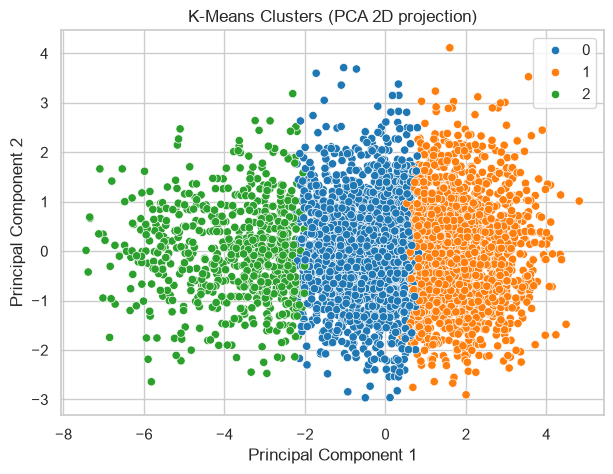

In [235]:
# Choose K after inspecting the plots; here K=3 is a demonstration choice.
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_cluster)
print("Silhouette score for K=3:", silhouette_score(X_cluster, kmeans_labels))
clustered = df.copy()
clustered["KMeans_Cluster"] = kmeans_labels
display(clustered.groupby("KMeans_Cluster")[cluster_cols].mean())

# 2D PCA view of clusters
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
cluster_2d = pca2.fit_transform(X_cluster)
plt.figure(figsize=(7, 5))
sns.scatterplot(x=cluster_2d[:, 0], y=cluster_2d[:, 1], hue=kmeans_labels, palette="tab10")
plt.title("K-Means Clusters (PCA 2D projection)")
plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
plt.show()

## UNIT V – Dimensionality Reduction and Neural Networks
### PCA – Principal Component Analysis

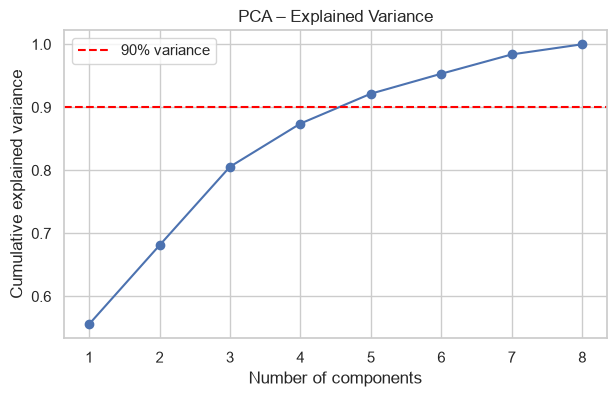

Explained variance ratio: [0.55569419 0.12530302 0.12464891 0.06850994 0.04742597 0.03167897
 0.03063892 0.01610008]


In [236]:
# PCA on standardized numeric variables
pca_cols = ["Age", "Daily_Usage_Hours", "Weekend_Extra_Hours",
            "Sleep_Duration_Hours", "Sleep_Quality_Score",
            "Perceived_Stress_Score", "Mental_Health_Index",
            "Academic_Performance_GPA"]
pca_frame = df[pca_cols].copy().fillna(df[pca_cols].median())
X_pca_scaled = StandardScaler().fit_transform(pca_frame)

pca_full = PCA()
pca_full.fit(X_pca_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var)+1), cum_var, marker="o")
plt.axhline(0.90, color="red", linestyle="--", label="90% variance")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA – Explained Variance"); plt.legend(); plt.show()
print("Explained variance ratio:", pca_full.explained_variance_ratio_)

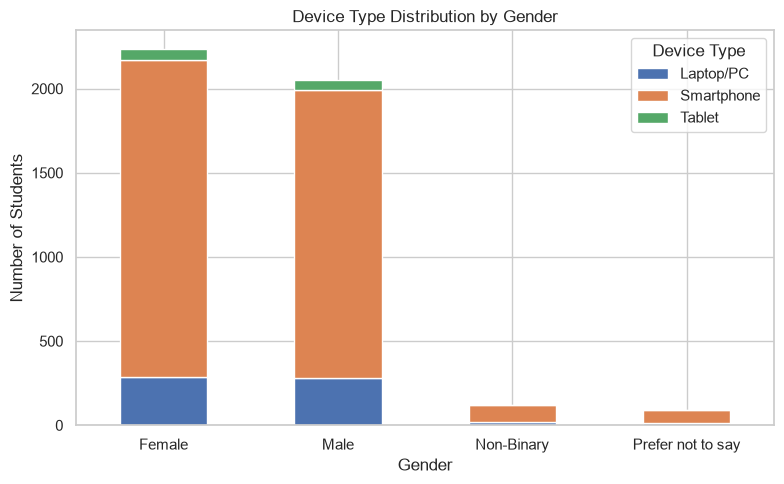

In [237]:
device_gender = pd.crosstab(df["Gender"], df["Device_Type"])
device_gender.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.title("Device Type Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.legend(title="Device Type")
plt.tight_layout()
plt.show()

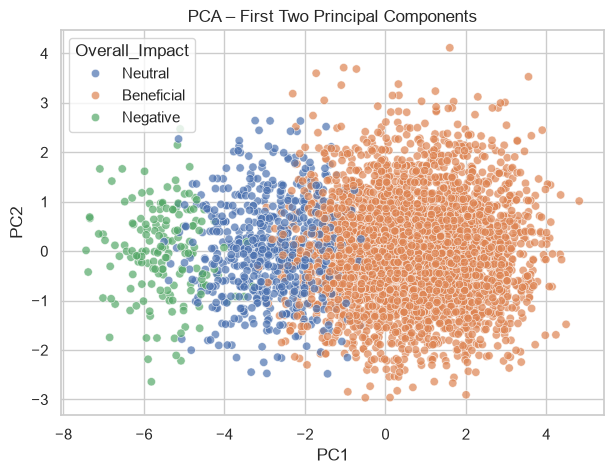

Variance explained by 2 components: 0.6809972095319933


In [238]:
# Reduce to 2 components and visualize
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_pca_scaled)
pca_df = pd.DataFrame(X_pca_2, columns=["PC1", "PC2"])
pca_df["Overall_Impact"] = df["Overall_Impact"].values
plt.figure(figsize=(7, 5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Overall_Impact", alpha=.7)
plt.title("PCA – First Two Principal Components")
plt.show()
print("Variance explained by 2 components:", pca_2.explained_variance_ratio_.sum())

### Feedforward Neural Network / Multi-Layer Perceptron (MLP)

\n===== Feedforward Neural Network / MLP =====
Accuracy: 0.9811111111111112
Precision (macro): 0.9554921478701965
Recall (macro): 0.9445317135845679
F1 (macro): 0.94993390361378
              precision    recall  f1-score   support

  Beneficial       0.99      0.99      0.99       736
    Negative       0.94      0.91      0.92        33
     Neutral       0.94      0.93      0.93       131

    accuracy                           0.98       900
   macro avg       0.96      0.94      0.95       900
weighted avg       0.98      0.98      0.98       900



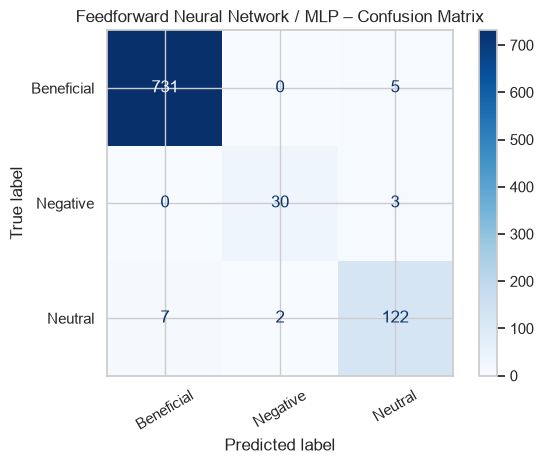

Log Loss: 0.061117944681497643
ROC AUC (macro OVR): 0.9975232507706583


In [239]:
mlp_model = evaluate_classifier(
    "Feedforward Neural Network / MLP",
    MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu",
                  solver="adam", max_iter=500, early_stopping=True,
                  random_state=RANDOM_STATE)
)


### Bias-variance intuition with learning curve

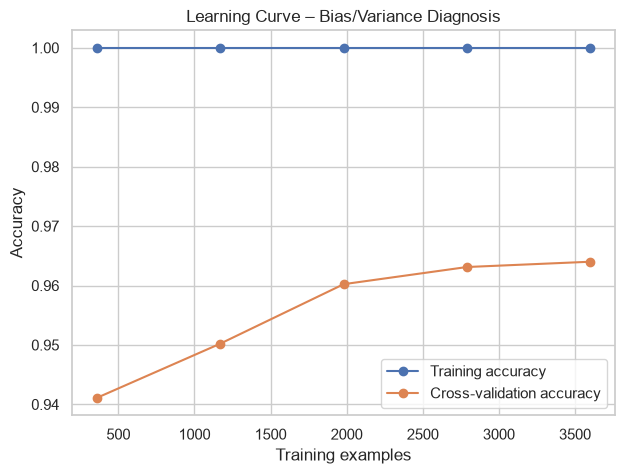

In [240]:
# Learning curve for a decision tree. Training vs cross-validation scores show
# whether the model may be overfitting (large gap) or underfitting (both low).
lc_pipe = Pipeline([
    ("preprocess", make_preprocessor(Xc_train)),
    ("model", DecisionTreeClassifier(max_depth=None, random_state=RANDOM_STATE))
])
sizes, train_scores, valid_scores = learning_curve(
    lc_pipe, Xc, yc, cv=5, scoring="accuracy",
    train_sizes=np.linspace(0.1, 1.0, 5), n_jobs=-1
)
plt.figure(figsize=(7, 5))
plt.plot(sizes, train_scores.mean(axis=1), marker="o", label="Training accuracy")
plt.plot(sizes, valid_scores.mean(axis=1), marker="o", label="Cross-validation accuracy")
plt.xlabel("Training examples"); plt.ylabel("Accuracy")
plt.title("Learning Curve – Bias/Variance Diagnosis")
plt.legend(); plt.show()

### Bagging, Boosting and Random Forest
All models use the same training/test split and preprocessing.

In [241]:
ensemble_models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=100, random_state=RANDOM_STATE
    ),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced"
    )
}

ensemble_results = []
ensemble_pipes = {}
for name, estimator in ensemble_models.items():
    pipe = Pipeline([
        ("preprocess", make_preprocessor(Xc_train)),
        ("model", estimator)
    ])
    pipe.fit(Xc_train, yc_train)
    pred = pipe.predict(Xc_test)
    ensemble_pipes[name] = pipe
    ensemble_results.append({
        "Model": name,
        "Accuracy": accuracy_score(yc_test, pred),
        "Precision_macro": precision_score(yc_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(yc_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(yc_test, pred, average="macro", zero_division=0)
    })
ensemble_results = pd.DataFrame(ensemble_results).sort_values("F1_macro", ascending=False)
display(ensemble_results)

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Bagging,0.977778,0.934363,0.938990,0.936591
2,Gradient Boosting,0.973333,0.933482,0.937178,0.935312
1,AdaBoost,0.962222,0.917861,0.917536,0.916027
3,Random Forest,0.960000,0.905566,0.926279,0.914602


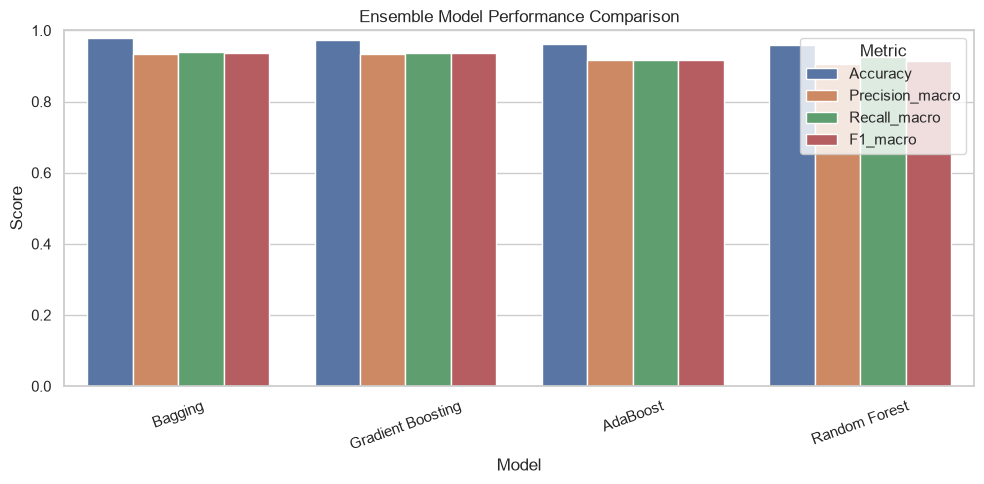

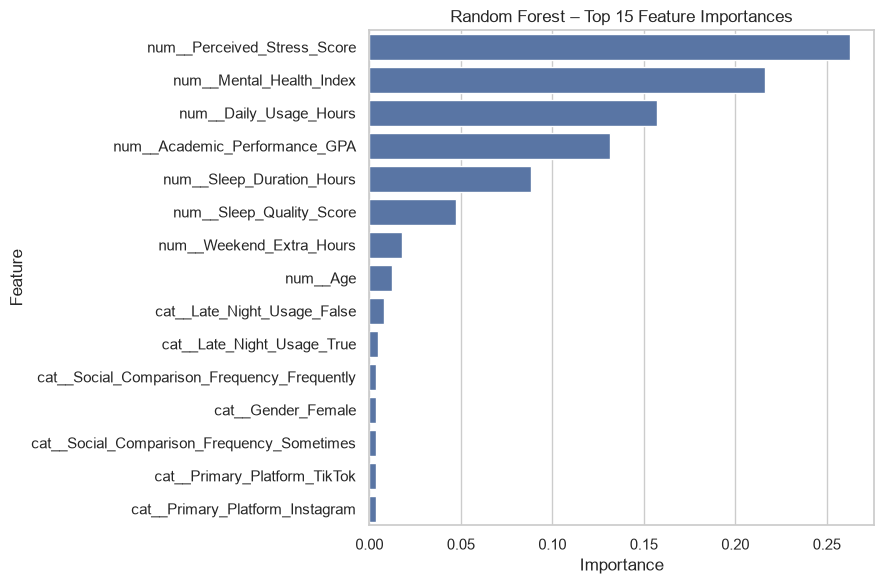

In [242]:
# Graphical comparison of ensemble models
plot_data = ensemble_results.melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_data, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1)
plt.title("Ensemble Model Performance Comparison")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

# Random Forest feature importance (top 15)
rf_pipe = ensemble_pipes["Random Forest"]
rf = rf_pipe.named_steps["model"]
feature_names = rf_pipe.named_steps["preprocess"].get_feature_names_out()
importance = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 6))
sns.barplot(x=importance.values, y=importance.index)
plt.title("Random Forest – Top 15 Feature Importances")
plt.xlabel("Importance"); plt.ylabel("Feature")
plt.tight_layout(); plt.show()

## Final practical: Compare classification algorithms in one table

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Logistic Regression,0.981111,0.955492,0.944532,0.949934
5,MLP,0.981111,0.955492,0.944532,0.949934
4,SVM,0.972222,0.942764,0.922894,0.932528
6,Random Forest,0.967778,0.939006,0.924456,0.931616
3,Decision Tree,0.964444,0.906662,0.900427,0.903120
1,KNN,0.934444,0.886076,0.818704,0.849545
2,Naive Bayes,0.923333,0.798529,0.900065,0.842265


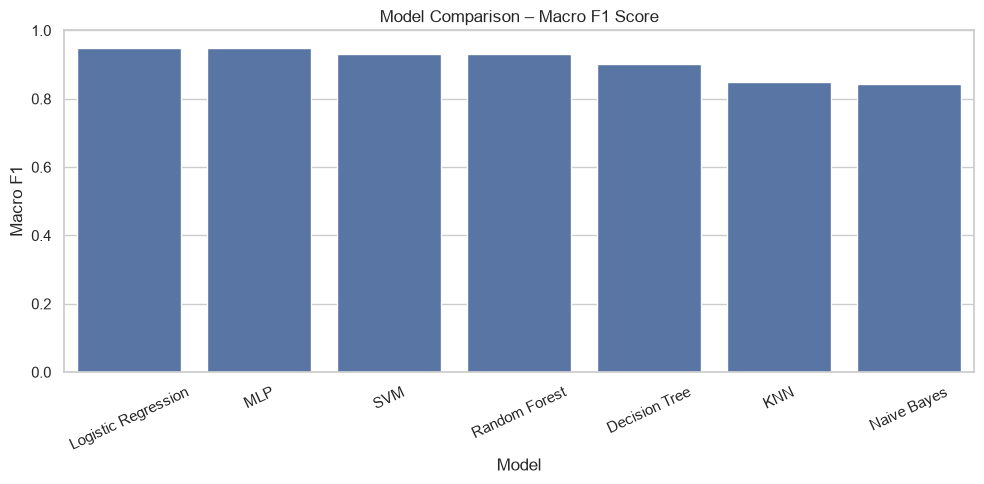

In [243]:
models_to_compare = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500,
                         early_stopping=True, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
}
comparison = []
for name, estimator in models_to_compare.items():
    pipe = Pipeline([("preprocess", make_preprocessor(Xc_train)), ("model", estimator)])
    pipe.fit(Xc_train, yc_train)
    pred = pipe.predict(Xc_test)
    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(yc_test, pred),
        "Precision_macro": precision_score(yc_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(yc_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(yc_test, pred, average="macro", zero_division=0)
    })
comparison_df = pd.DataFrame(comparison).sort_values("F1_macro", ascending=False)
display(comparison_df)

plt.figure(figsize=(10, 5))
sns.barplot(data=comparison_df, x="Model", y="F1_macro")
plt.title("Model Comparison – Macro F1 Score")
plt.ylabel("Macro F1"); plt.xticks(rotation=25); plt.ylim(0, 1)
plt.tight_layout(); plt.show()

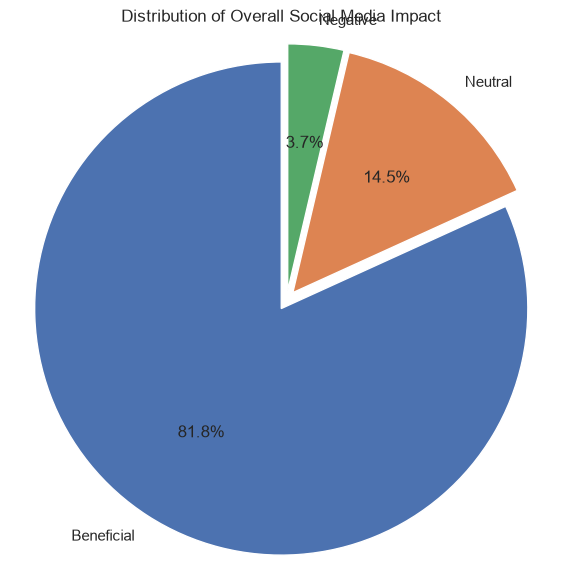

In [244]:
# Shows percentage share of Beneficial, Neutral and Negative impact.
counts = df["Overall_Impact"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(counts.values, labels=counts.index, autopct="%1.1f%%",
        startangle=90, explode=[0.04] * len(counts))
plt.title("Distribution of Overall Social Media Impact")
plt.axis("equal")
plt.show()

## Quick practical notes / viva reminders

- **Regression target used:** `Academic_Performance_GPA` (continuous).
- **Classification target used:** `Overall_Impact` (3 classes).
- **Identifier:** `Student_ID` is removed because it is not a meaningful predictor.
- **Missing values:** median imputation for numeric fields and most-frequent imputation for categorical fields.
- **Encoding:** One-Hot Encoding for categorical features.
- **Scaling:** StandardScaler for algorithms sensitive to feature scale (KNN, SVM, Logistic Regression, MLP, PCA and clustering).
- **Regression metrics:** MAE, MSE, RMSE and R².
- **Classification metrics:** Accuracy, Log Loss, ROC AUC, Precision, Recall, F1 and Confusion Matrix.
- **Clustering:** K-Means, Elbow, Silhouette, Agglomerative clustering and linkage dendrograms.
- **Association rules caveat:** a proper market basket requires transaction-level data with transaction IDs and item names. This dataset supports only proxy co-occurrence rules.
- **Reproducibility:** random state is set to 42 where applicable.

### If a package import fails
Install the missing package in a notebook cell, e.g. `%pip install mlxtend statsmodels scipy scikit-learn`.